# Introduction

## Problem Statement
- The passengers who use flights to travel to different destinations often see a lot of variation in the prices. The problem that they face is regarding the selection of the flight. We will use ML to predict the flight prices, which will help the consumer is making a selection.

## Objective
- The aim of this project is to build a Machine Learning Model to predict the flight prices based on the different features like Date, Duration, Total Stops etc for different destinations.
- The predictions are intended to assist the passengers to decide which flight or airline to take and plan their journey, and for the airlines to decide execute their pricing strategies. 

## Input Features
- If we see the Input Features, we have the Airline Company, Date, the Source of the flight(The Departure City), the Destination(The Arrival City), Route, Departure and Arrival Time, Duration, Total Stops, Additional Information.

## Output Feature (Target Variable)
- The actual Price of the flight ticket.

# Basic Information
## Importing Necessary Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
import warnings
warnings.filterwarnings('ignore')

## Loading the CSV File

In [3]:
flight = pd.read_excel("Flight_Fare.xlsx")

In [4]:
flight.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [5]:
flight.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


# Checking the Shape of the Dataset

In [6]:
flight.shape

(10683, 11)

# Checking for Null Values

In [7]:
flight.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

### Removing columns with null values

In [8]:
flight[flight['Route'].isna() | flight['Total_Stops'].isna()]

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
9039,Air India,6/05/2019,Delhi,Cochin,NaN,09:45,09:25 07 May,23h 40m,NaN,No info,7480


In [9]:
flight.dropna(inplace=True)
flight.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              0
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        0
Additional_Info    0
Price              0
dtype: int64

In [10]:
flight.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10682 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10682 non-null  object
 1   Date_of_Journey  10682 non-null  object
 2   Source           10682 non-null  object
 3   Destination      10682 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10682 non-null  object
 6   Arrival_Time     10682 non-null  object
 7   Duration         10682 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10682 non-null  object
 10  Price            10682 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 1001.4+ KB


# Describing the Continuous Variable

In [11]:
flight.describe()

,Price
count,10682.000000
mean,9087.214567
std,4611.548810
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


- Seeing the Description, the mean price of the tickets is at 9087.21 Rs which indicates that on average the customers pay around 9000 Rs for the fare.
- Also if we see the minimum cost, it is at 1759 Rs whereas the maximum cost is almost at 80000 Rs, this shows quite a large difference in the prices being paid by the customers.
- If we see the 25th, 50th and 75th quartiles, they are at 5277 Rs, 8372 Rs and 12373 Rs. This indicates that there is not much difference in the amount being paid in comparison to all quartiles.

In [13]:
flight.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


# Exploratory Data Analysis & Feature Engineering

###  Extracting Date and month

In [14]:
flight.Date_of_Journey.unique()     # Checking unique values in the column Date_of_Journey

array(['24/03/2019', '1/05/2019', '9/06/2019', '12/05/2019', '01/03/2019',
       '24/06/2019', '12/03/2019', '27/05/2019', '1/06/2019',
       '18/04/2019', '9/05/2019', '24/04/2019', '3/03/2019', '15/04/2019',
       '12/06/2019', '6/03/2019', '21/03/2019', '3/04/2019', '6/05/2019',
       '15/05/2019', '18/06/2019', '15/06/2019', '6/04/2019',
       '18/05/2019', '27/06/2019', '21/05/2019', '06/03/2019',
       '3/06/2019', '15/03/2019', '3/05/2019', '9/03/2019', '6/06/2019',
       '24/05/2019', '09/03/2019', '1/04/2019', '21/04/2019',
       '21/06/2019', '27/03/2019', '18/03/2019', '12/04/2019',
       '9/04/2019', '1/03/2019', '03/03/2019', '27/04/2019'], dtype=object)

In [15]:
flight['Date_of_Journey'] = pd.to_datetime(flight['Date_of_Journey'], dayfirst=True, errors='coerce')
# Converting the format of the date of journey

In [16]:
print(flight['Date_of_Journey'].head())

0   2019-03-24
1   2019-05-01
2   2019-06-09
3   2019-05-12
4   2019-03-01
Name: Date_of_Journey, dtype: datetime64[ns]


In [17]:
flight.Date_of_Journey.unique()  # Converted to YYYY-MM-DD

<DatetimeArray>
['2019-03-24 00:00:00', '2019-05-01 00:00:00', '2019-06-09 00:00:00',
 '2019-05-12 00:00:00', '2019-03-01 00:00:00', '2019-06-24 00:00:00',
 '2019-03-12 00:00:00', '2019-05-27 00:00:00', '2019-06-01 00:00:00',
 '2019-04-18 00:00:00', '2019-05-09 00:00:00', '2019-04-24 00:00:00',
 '2019-03-03 00:00:00', '2019-04-15 00:00:00', '2019-06-12 00:00:00',
 '2019-03-06 00:00:00', '2019-03-21 00:00:00', '2019-04-03 00:00:00',
 '2019-05-06 00:00:00', '2019-05-15 00:00:00', '2019-06-18 00:00:00',
 '2019-06-15 00:00:00', '2019-04-06 00:00:00', '2019-05-18 00:00:00',
 '2019-06-27 00:00:00', '2019-05-21 00:00:00', '2019-06-03 00:00:00',
 '2019-03-15 00:00:00', '2019-05-03 00:00:00', '2019-03-09 00:00:00',
 '2019-06-06 00:00:00', '2019-05-24 00:00:00', '2019-04-01 00:00:00',
 '2019-04-21 00:00:00', '2019-06-21 00:00:00', '2019-03-27 00:00:00',
 '2019-03-18 00:00:00', '2019-04-12 00:00:00', '2019-04-09 00:00:00',
 '2019-04-27 00:00:00']
Length: 40, dtype: datetime64[ns]

In [18]:
# Extracting the day and month seperately from date of journey for further analysis
flight['Journey_Day'] = pd.to_datetime(flight.Date_of_Journey, format='%d/%m/%y').dt.day
flight['Journey_Month'] = pd.to_datetime(flight.Date_of_Journey, format='%d/%m/%y').dt.month
flight.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month
0,IndiGo,2019-03-24,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3
1,Air India,2019-05-01,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662,1,5
2,Jet Airways,2019-06-09,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882,9,6
3,IndiGo,2019-05-12,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218,12,5
4,IndiGo,2019-03-01,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302,1,3


### Extracting Departure and Arrival time

In [19]:
# Extracting departure hour and minutes seperately
flight['Dep_hour'] = pd.to_datetime(flight.Dep_Time).dt.hour
flight['Dep_minute'] = pd.to_datetime(flight.Dep_Time).dt.minute

In [20]:
flight.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Dep_hour,Dep_minute
0,IndiGo,2019-03-24,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3,22,20
1,Air India,2019-05-01,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662,1,5,5,50
2,Jet Airways,2019-06-09,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882,9,6,9,25
3,IndiGo,2019-05-12,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218,12,5,18,5
4,IndiGo,2019-03-01,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302,1,3,16,50


### Dropping Date_of_Journey, Dep_Time, Arrival_Time

In [21]:
# Extracting arrival hour and minutes seperately
flight['Arrival_hour'] = pd.to_datetime(flight.Arrival_Time).dt.hour
flight['Arrival_minute'] = pd.to_datetime(flight.Arrival_Time).dt.minute
flight.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Dep_hour,Dep_minute,Arrival_hour,Arrival_minute
0,IndiGo,2019-03-24,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3,22,20,1,10
1,Air India,2019-05-01,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662,1,5,5,50,13,15
2,Jet Airways,2019-06-09,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882,9,6,9,25,4,25
3,IndiGo,2019-05-12,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218,12,5,18,5,23,30
4,IndiGo,2019-03-01,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302,1,3,16,50,21,35


In [22]:
# Dropping the column Date of Journey since the data has already been extracted as Journey Month and Journey Day
flight.drop(columns = ['Date_of_Journey'], inplace = True )

In [23]:
# Dropping the column Departure Time and Arrival Time since the data has already been extracted as dep_hour, dep_minute, arrival_hour and arrival_minute
flight.drop(columns=['Dep_Time','Arrival_Time'],inplace = True)

In [24]:
flight.head()

,Airline,Source,Destination,Route,Duration,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Dep_hour,Dep_minute,Arrival_hour,Arrival_minute
0,IndiGo,Banglore,New Delhi,BLR → DEL,2h 50m,non-stop,No info,3897,24,3,22,20,1,10
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,7h 25m,2 stops,No info,7662,1,5,5,50,13,15
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,19h,2 stops,No info,13882,9,6,9,25,4,25
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,5h 25m,1 stop,No info,6218,12,5,18,5,23,30
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,4h 45m,1 stop,No info,13302,1,3,16,50,21,35


### Extracting the hours and minutes from Duration Column

In [25]:
# Checking the Unique values in Duration Column
flight.Duration.unique()

array(['2h 50m', '7h 25m', '19h', '5h 25m', '4h 45m', '2h 25m', '15h 30m',
       '21h 5m', '25h 30m', '7h 50m', '13h 15m', '2h 35m', '2h 15m',
       '12h 10m', '26h 35m', '4h 30m', '22h 35m', '23h', '20h 35m',
       '5h 10m', '15h 20m', '2h 55m', '13h 20m', '15h 10m', '5h 45m',
       '5h 55m', '13h 25m', '22h', '5h 30m', '10h 25m', '5h 15m',
       '2h 30m', '6h 15m', '11h 55m', '11h 5m', '8h 30m', '22h 5m',
       '2h 45m', '12h', '16h 5m', '19h 55m', '3h 15m', '25h 20m', '3h',
       '16h 15m', '15h 5m', '6h 30m', '25h 5m', '12h 25m', '27h 20m',
       '10h 15m', '10h 30m', '1h 30m', '1h 25m', '26h 30m', '7h 20m',
       '13h 30m', '5h', '19h 5m', '14h 50m', '2h 40m', '22h 10m',
       '9h 35m', '10h', '21h 20m', '18h 45m', '12h 20m', '18h', '9h 15m',
       '17h 30m', '16h 35m', '12h 15m', '7h 30m', '24h', '8h 55m',
       '7h 10m', '14h 30m', '30h 20m', '15h', '12h 45m', '10h 10m',
       '15h 25m', '14h 5m', '20h 15m', '23h 10m', '18h 10m', '16h',
       '2h 20m', '8h', '16h 5

In [26]:
# Ensuring the 'Duration' column is a string type
flight['Duration'] = flight['Duration'].astype(str)

# Extract hours from Duration
flight['Duration_Hours'] = flight['Duration'].str.extract(r'(\d+)h', expand=False).fillna(0).astype(int)

# Extract minutes from Duration
flight['Duration_Minutes'] = flight['Duration'].str.extract(r'(\d+)m', expand=False).fillna(0).astype(int)

In [27]:
flight.head()

,Airline,Source,Destination,Route,Duration,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Dep_hour,Dep_minute,Arrival_hour,Arrival_minute,Duration_Hours,Duration_Minutes
0,IndiGo,Banglore,New Delhi,BLR → DEL,2h 50m,non-stop,No info,3897,24,3,22,20,1,10,2,50
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,7h 25m,2 stops,No info,7662,1,5,5,50,13,15,7,25
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,19h,2 stops,No info,13882,9,6,9,25,4,25,19,0
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,5h 25m,1 stop,No info,6218,12,5,18,5,23,30,5,25
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,4h 45m,1 stop,No info,13302,1,3,16,50,21,35,4,45


In [28]:
# Dropping the column Duration after extracting the data
flight.drop(columns=['Duration'],inplace = True)

In [29]:
flight.head()

,Airline,Source,Destination,Route,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Dep_hour,Dep_minute,Arrival_hour,Arrival_minute,Duration_Hours,Duration_Minutes
0,IndiGo,Banglore,New Delhi,BLR → DEL,non-stop,No info,3897,24,3,22,20,1,10,2,50
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,2 stops,No info,7662,1,5,5,50,13,15,7,25
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,2 stops,No info,13882,9,6,9,25,4,25,19,0
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,1 stop,No info,6218,12,5,18,5,23,30,5,25
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,1 stop,No info,13302,1,3,16,50,21,35,4,45


In [30]:
unique_values = flight['Airline'].unique
print(unique_values)

<bound method Series.unique of 0             IndiGo
1          Air India
2        Jet Airways
3             IndiGo
4             IndiGo
            ...     
10678       Air Asia
10679      Air India
10680    Jet Airways
10681        Vistara
10682      Air India
Name: Airline, Length: 10682, dtype: object>


# Insights from Univariate Analysis

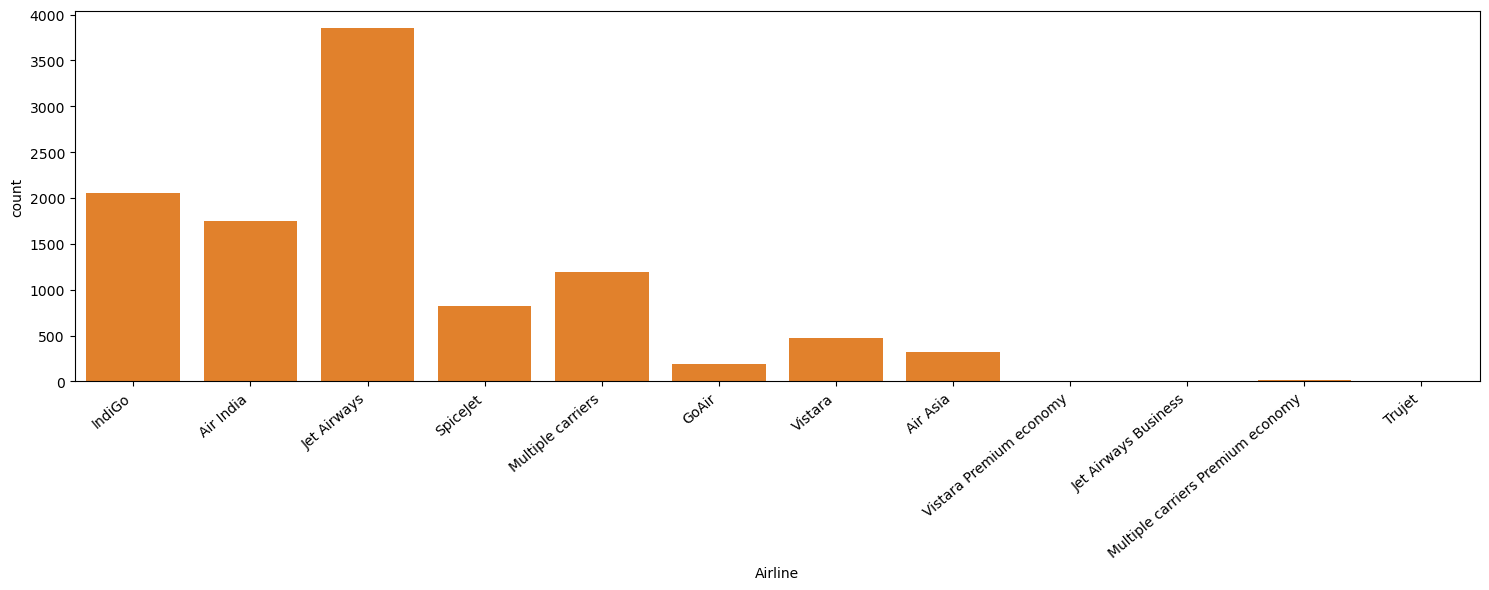

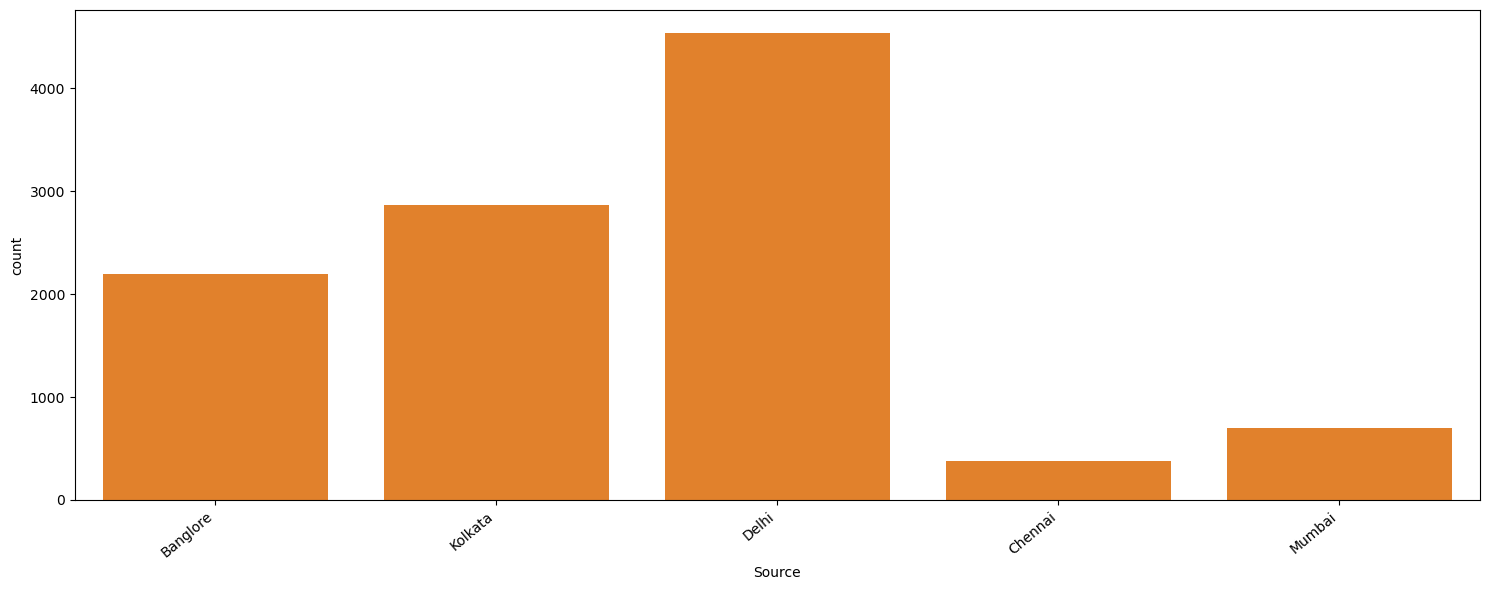

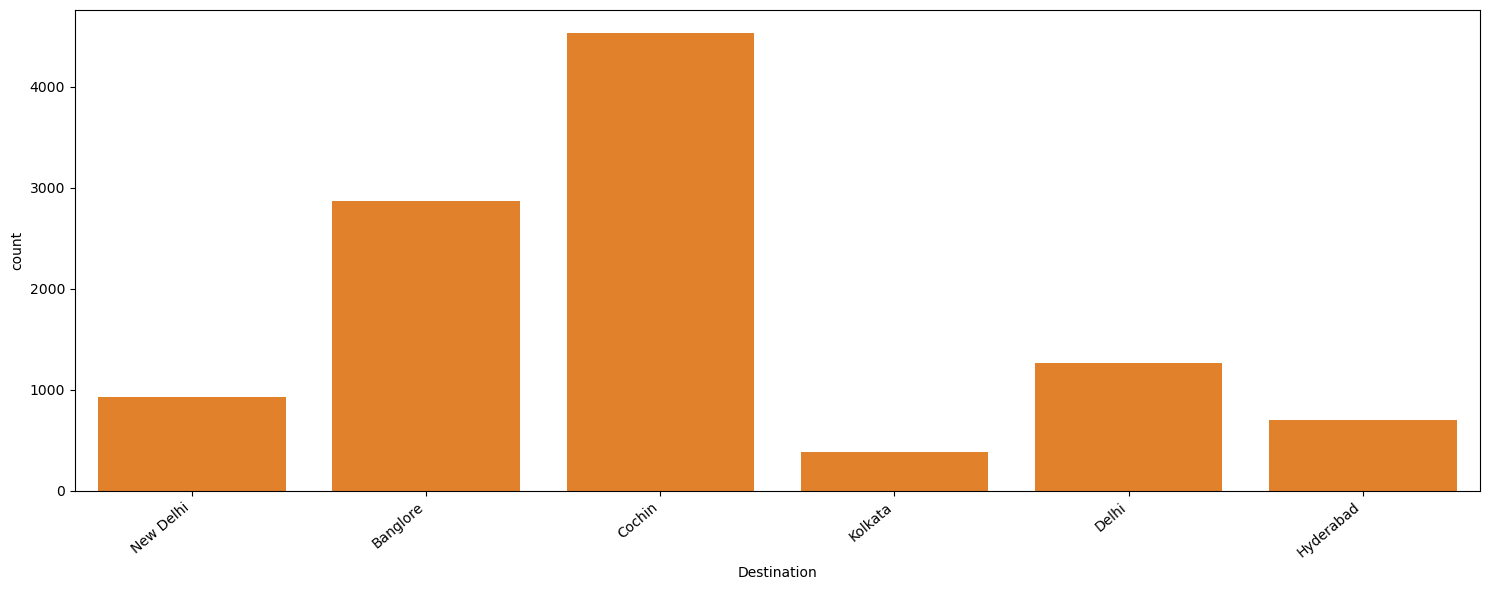

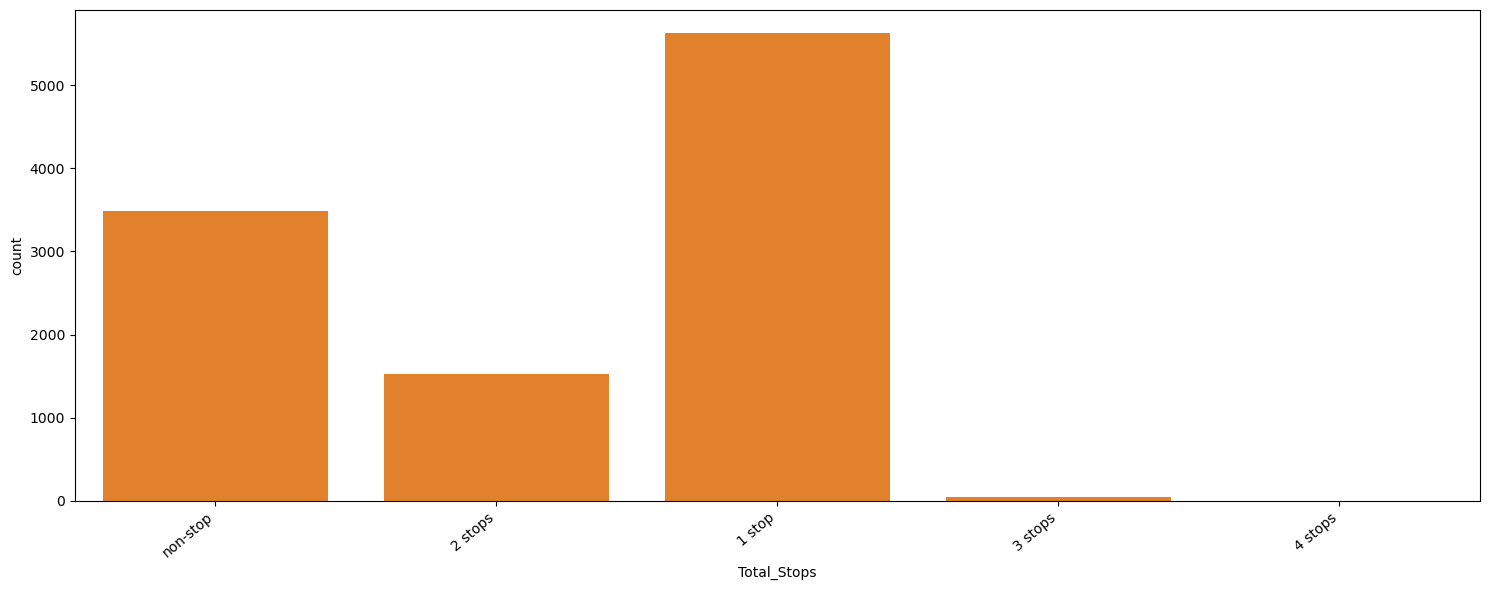

In [31]:
for i in ['Airline','Source','Destination','Total_Stops']:
    plt.figure(figsize = (15,6))
    sns.countplot(data = flight, x= i)
    ax = sns.countplot(x = i, data = flight.sort_values('Price', ascending = True ))
    ax.set_xticklabels(ax.get_xticklabels(), rotation = 40, ha = 'right') 
    plt.tight_layout()
    plt.show()
    print('\n\n')                  

#### Graph 1
- This graph shows the number of flights of each company which are flying. If we see the graph, the highest number of flights belong to Jet Airways followed by Indigo and Air India.
- The least values is for the last 4 columns which are Viatara Premium Economy, Jet Airways Business, Multiple Carriers Premium Economy and Trujet.

#### Graph 2
- The second graph shows the location from where the flight begins its journey. Seeing the graph, most of the flights are from Delhi, followed by Kolkata.
- Seeing the graph, we can understand that the Delhi airport is among the busiest airports of the country.
- The least number of flights are from Chennai and Mumbai.

#### Graph 3
- Seeing the graph of the destinations, the highest value is for Cochin followed by Bangalore. This could be due to Cochin being an in demand tourist destination and Bangalore being the IT hub of the country.
- Also, if we see the graph, Kolkata has the least value.

#### Graph 4
- This graph shows the number of stops a flight makes. The highest count is for 1 stop followed by non-stop.
- The least value that can be seen if for 4 stops.

In [32]:
flight['Airline'].value_counts()

Airline
Jet Airways                          3849
IndiGo                               2053
Air India                            1751
Multiple carriers                    1196
SpiceJet                              818
Vistara                               479
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Vistara Premium economy                 3
Trujet                                  1
Name: count, dtype: int64

# Insights from Bivariate Analysis

### Bivariate analysis for Airline and Price

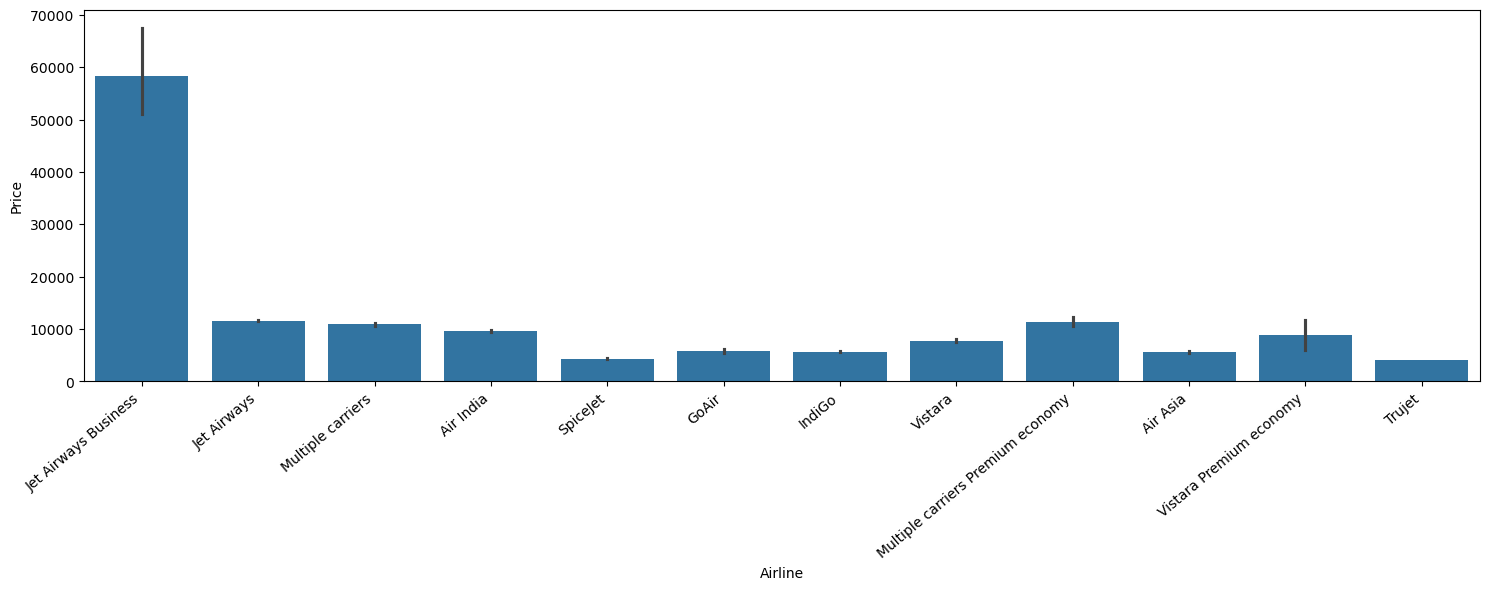

In [33]:
plt.figure(figsize = (15,6))
ax = sns.barplot(x = 'Airline', y = 'Price', data = flight.sort_values('Price',ascending = False))
ax.set_xticklabels(ax.get_xticklabels(), rotation = 40, ha = 'right') # Since names are long, we have rotated the names by 
                                                                      # 40 degrees to be able to see the full names 
plt.tight_layout()
plt.show()

- If we see the price variation based on the Airline, the highest price is seen in Jet Airways Business class which actually comes under premium airlines category. This could be due to the offering of premium services, food and comfortable seating.
- If we see the next highest category which is at around 10000, it is seen for Jet Airways, Multiple Carriers, Air India and Multiple Carriers Premium Economy. This could be due to the lower services compared to the premium category. This could also be due to the low operation and maintainance cost.
- The least prices can be seen for Spicejet and Trujet. This could possibly be due to the airlines being old and the services not being adequate. Also possibly because they dont offer full services. This could also be because they offer discounted fares to attract more passengers, and lower their prices during non peak seasons.
- The prices vary based on the size of the aircraft as well, and since we do not have that attribute either, we cannot get much insights.
- Since we do not have the attributes for peak seasons, we cannot get much insights from these charts.

### Bivariate analysis for Source and Price

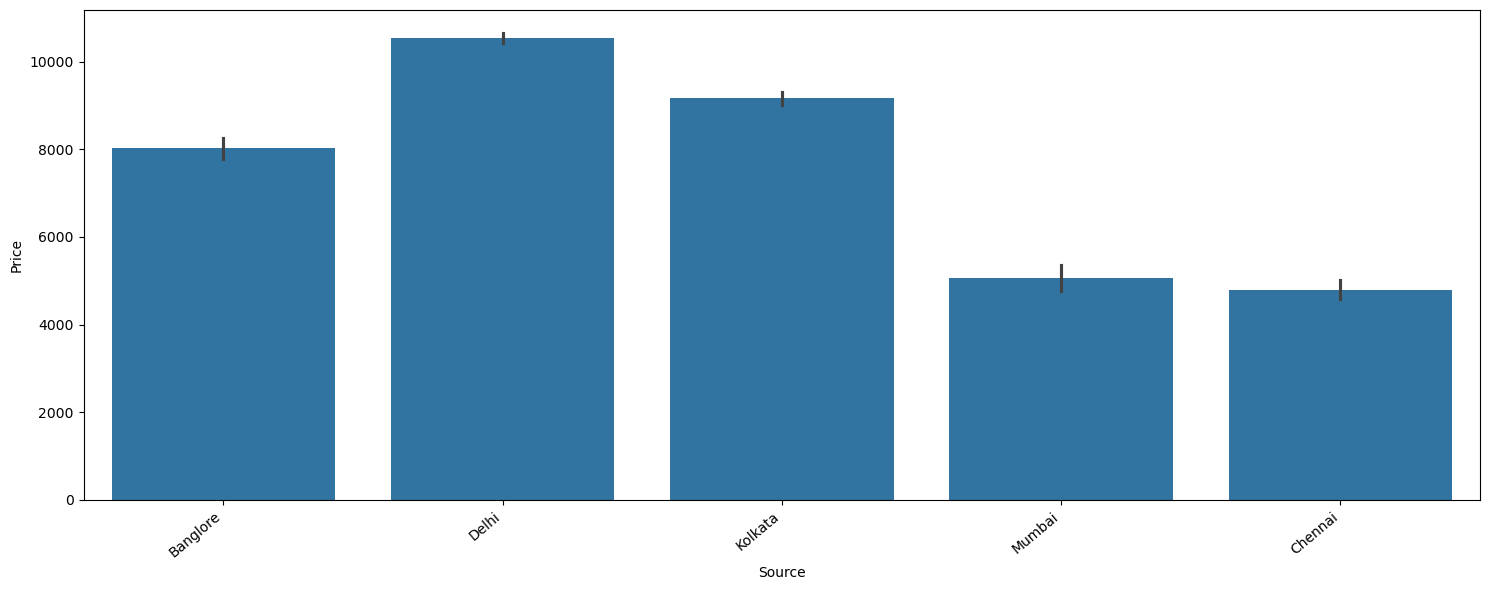

In [34]:
plt.figure(figsize = (15,6))
ax = sns.barplot(x = 'Source', y = 'Price', data = flight.sort_values('Price',ascending = False))
ax.set_xticklabels(ax.get_xticklabels(), rotation = 40, ha = 'right') 
plt.tight_layout()
plt.show()

- If we see the graph for Source of the flights, the highest number is for Delhi, which indicates that the flights from Delhi are the most expensive, which is followed by Kolkata. This indicates that there is a high travel demand from these locations.
- If we see the least cost of flights, it is for the flights from Chennai and Mumbai, which indicates that the flights going from Chennai and Mumbai are not very expensive. This could be due the strategy of attracting passengers to travel. 

### Bivariate analysis for Destination and Price

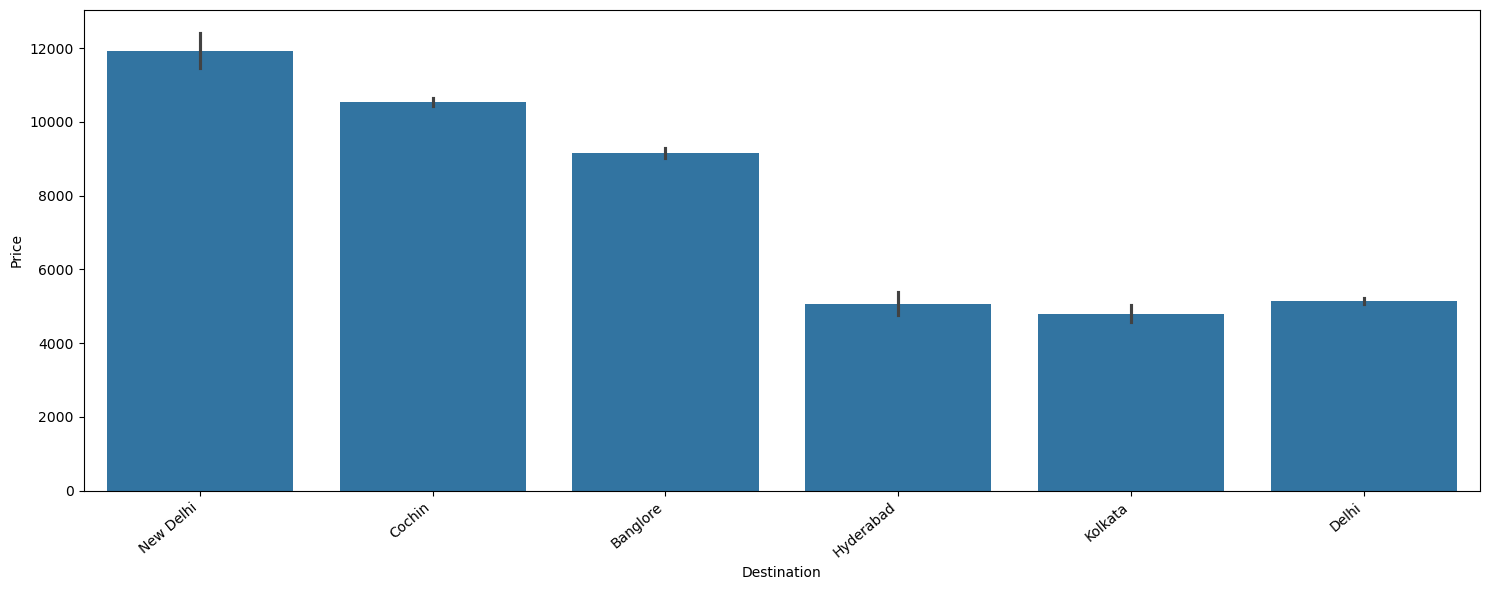

In [35]:
plt.figure(figsize = (15,6))
ax = sns.barplot(x = 'Destination', y = 'Price', data = flight.sort_values('Price',ascending = False))
ax.set_xticklabels(ax.get_xticklabels(), rotation = 40, ha = 'right') 
plt.tight_layout()
plt.show()

- If we see the price for New Delhi as a destination, it is the highest, followed by Cochin and Bangalore. This could be due to the high demand or services in these cities.
- If we see the lower prices, it can be seen for Hyderabad, Kolkata and Delhi. This could be due to lower demand, competitive pricing, or more frequent travel options.

### Bivariate analysis for Total_Stops and Price

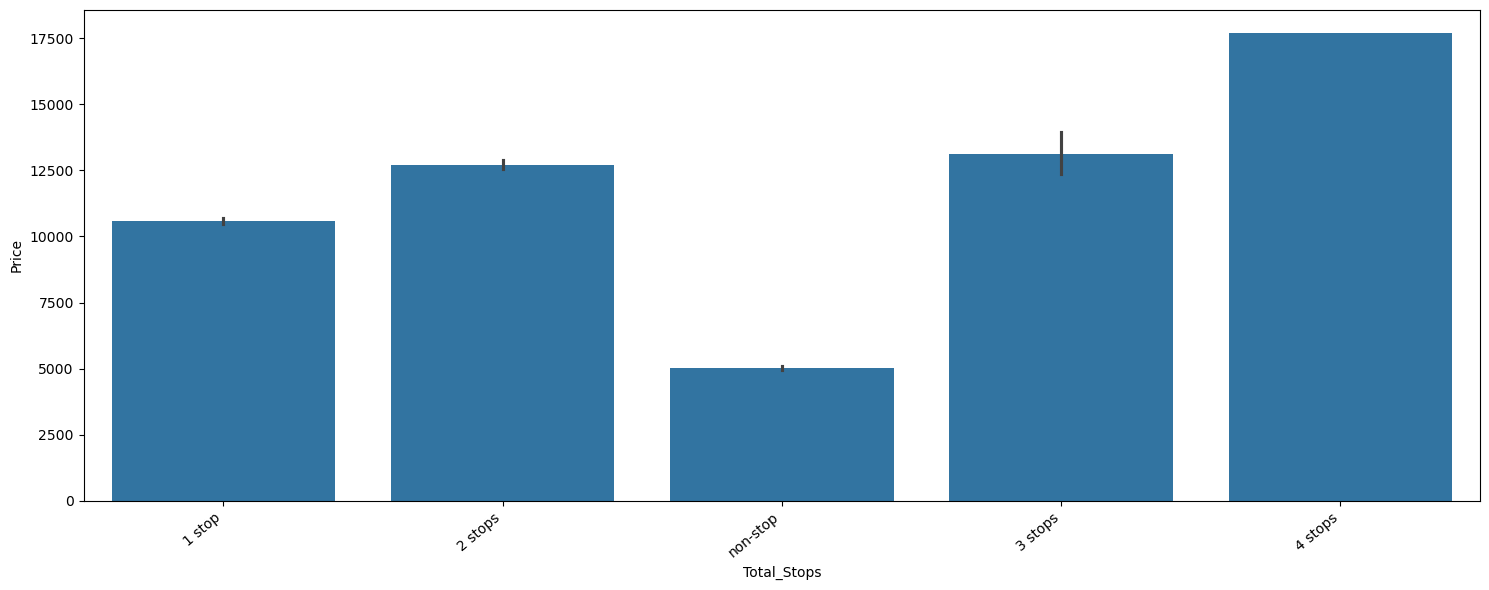

In [36]:
plt.figure(figsize = (15,6))
ax = sns.barplot(x = 'Total_Stops',y = 'Price', data = flight.sort_values('Price',ascending = False))
ax.set_xticklabels(ax.get_xticklabels(), rotation = 40, ha = 'right') 
plt.tight_layout()
plt.show()


- If we see the cost for total number of stops, it is highest for 4 stops, followed by 3 and 2 stops. This could be due to high cost of operation and fuel, which they cover from the tickets.
- If the number of stops is high, then the duration also increases which is not a preferable option by passengers. Despite this, the cost is still high for the passengers so that the airline does not face any losses.
- The next highest cost is for 2 and 3 stops followed by 1 stop.
- The least cost is for Non-Stop which is around 5000, which could be due to lower distances and lesser fuel consumption.

# Checking for Outliers 

#### Outliers in prices of airline Category

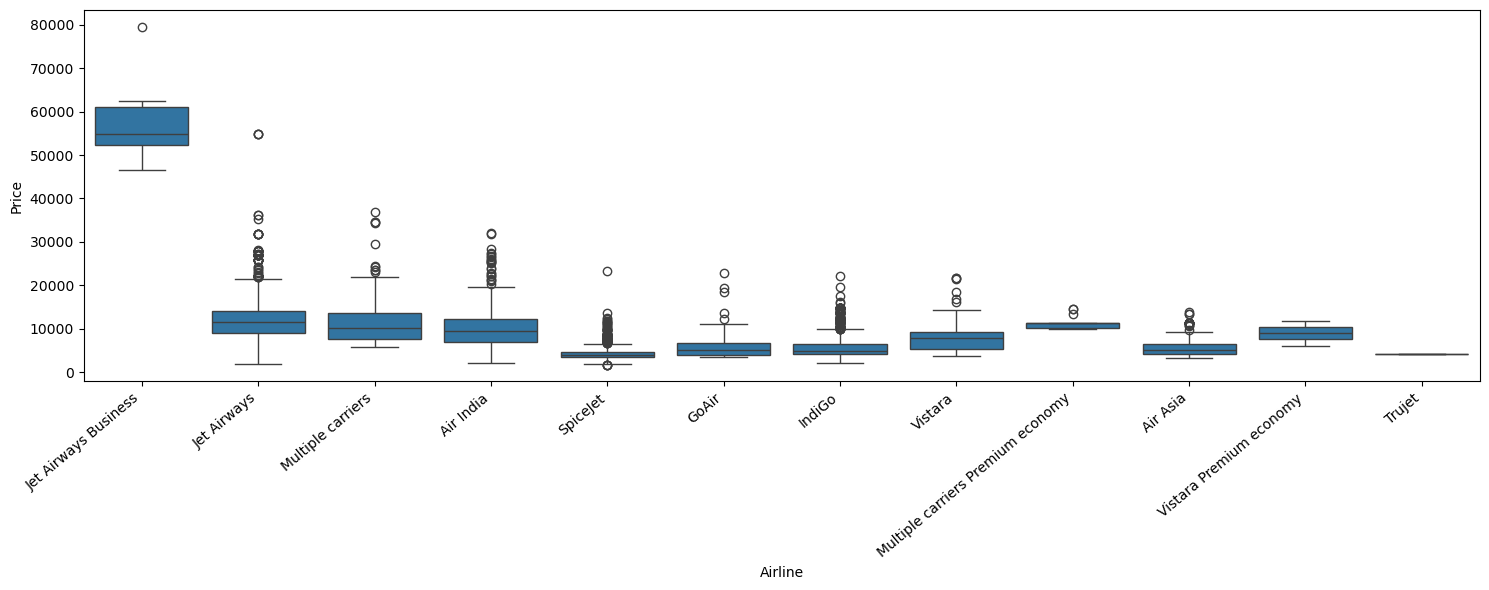

In [37]:
plt.figure(figsize = (15,6))
ax = sns.boxplot(x = 'Airline', y = 'Price', data = flight.sort_values('Price',ascending = False ))
ax.set_xticklabels(ax.get_xticklabels(), rotation = 40, ha = 'right') 
plt.tight_layout()
plt.show()

- The boxplot Clearly shows that the most expensive airline is Jet airways Business which indicates  premium services for business class travelers.
- Prices are concentrated between 50,000–60,000, with a few extreme outliers above 70,000 indian rupees.
- Jet Airways, Multiple Carriers, and Air India are similar pricing, while outleirs shows above 30,000 indian rupees.
- The outliers could be due to its classes (Premium), and its srvices.
- Yhe prices for vistara is slightly lower comparing to Vistarpremium economy. 
- The other Airways shows a value below 5,000 wile Trujet with the lowest price. 

#### Outliers in prices of Source Category

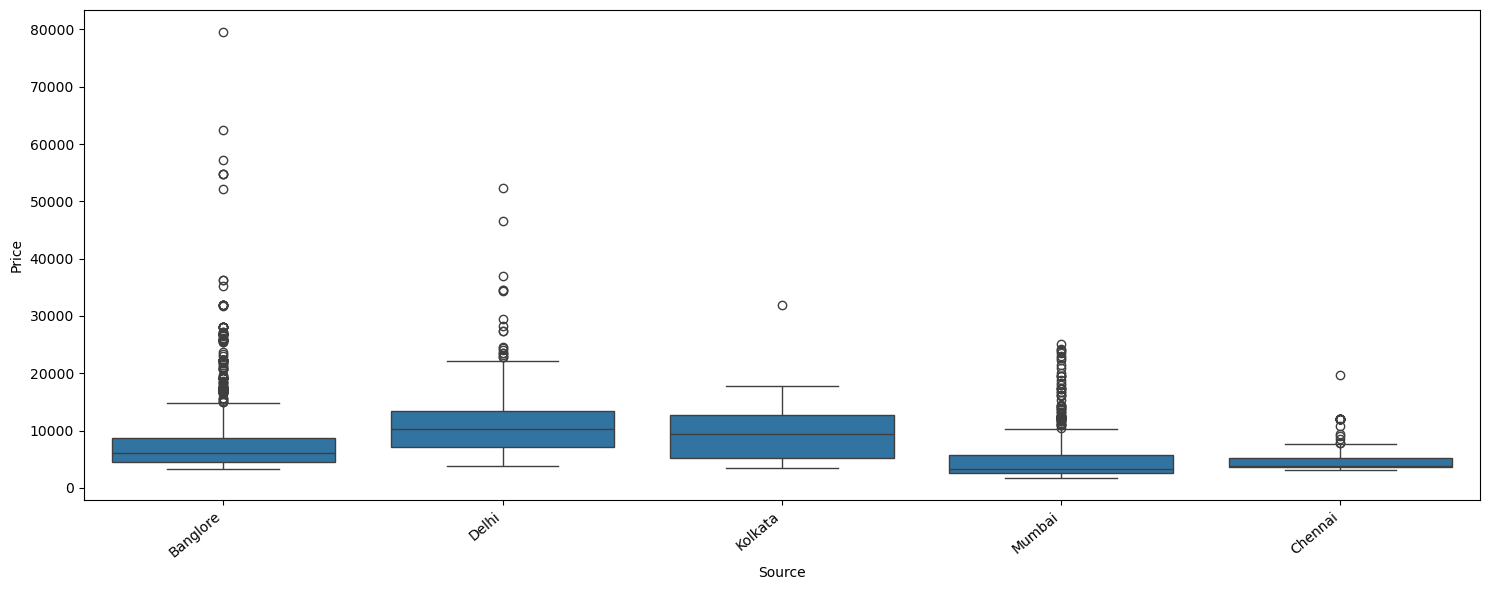

In [38]:
plt.figure(figsize = (15,6))
ax = sns.boxplot(x = 'Source', y = 'Price', data = flight.sort_values('Price',ascending = False ))
ax.set_xticklabels(ax.get_xticklabels(), rotation = 40, ha = 'right') 
plt.tight_layout()
plt.show()

- There are significant outliers for all the cities, especially Bangalore and Delhi, where prices are upto 80,000  and 50,000 respectively.
- Kolkata and Chennai have fewer extreme outliers compared to Delhi and Bangalore.
- Mumbai and Chennai consistently have lower prices with tighter interquartile ranges (IQRs), indicating stability.
-Bangalore and Delhi show larger spreads in prices, suggesting high variation in flight costs. This could be due to
High demand, Seasonal variations, or Multiple airlines with dynamic pricing strategies.

#### Outliers in prices of Destination Category

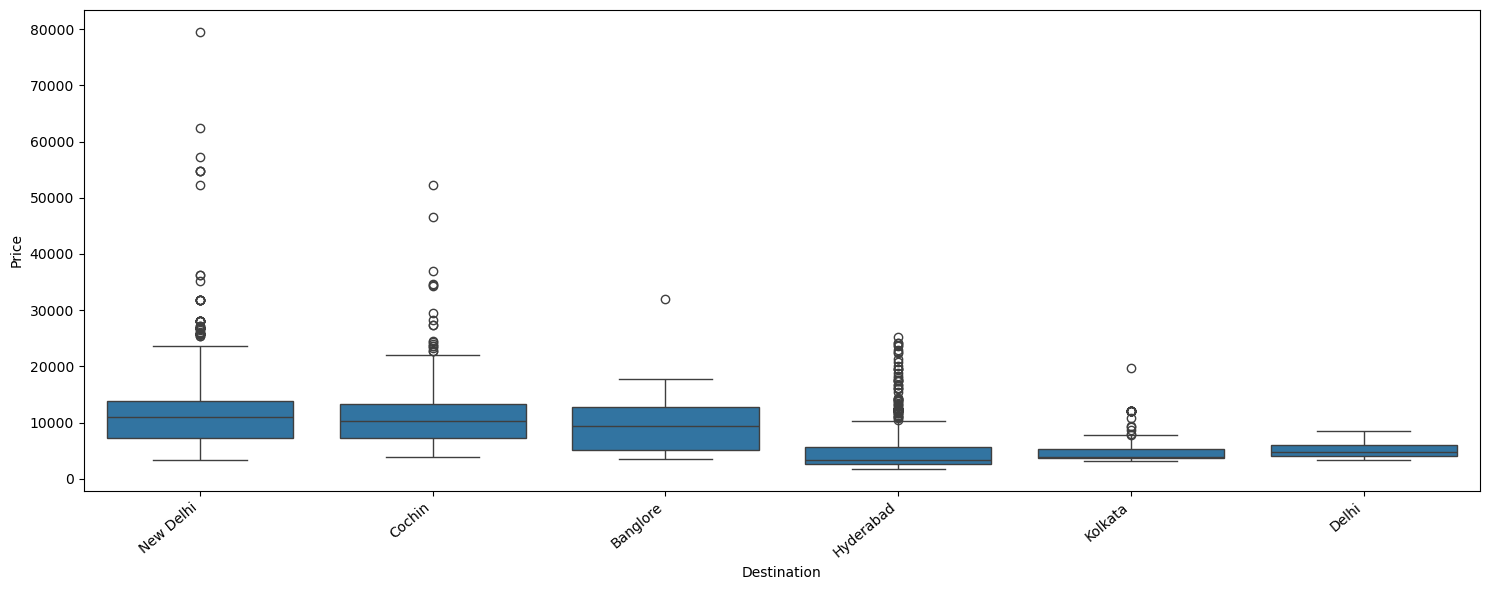

In [39]:
plt.figure(figsize = (15,6))
ax = sns.boxplot(x = 'Destination', y = 'Price', data = flight.sort_values('Price',ascending = False ))
ax.set_xticklabels(ax.get_xticklabels(), rotation = 40, ha = 'right') 
plt.tight_layout()
plt.show()

- There are significant outliers for all the cities, especially New Delhi and Cochin, where prices are upto 80,000 and 50,000 respectively.
- Kolkata and Bangalore have fewer extreme outliers compared to New Delhi and Cochin.
- Kolkata and Delhi consistently have lower prices with tighter interquartile ranges (IQRs), indicating stability.
- New Delhi and Cochin show larger spreads in prices, suggesting high variation in flight costs. This could be due to High demand, Seasonal variations, or Multiple airlines with dynamic pricing strategies.

#### Outliers in prices of Total Stops Category

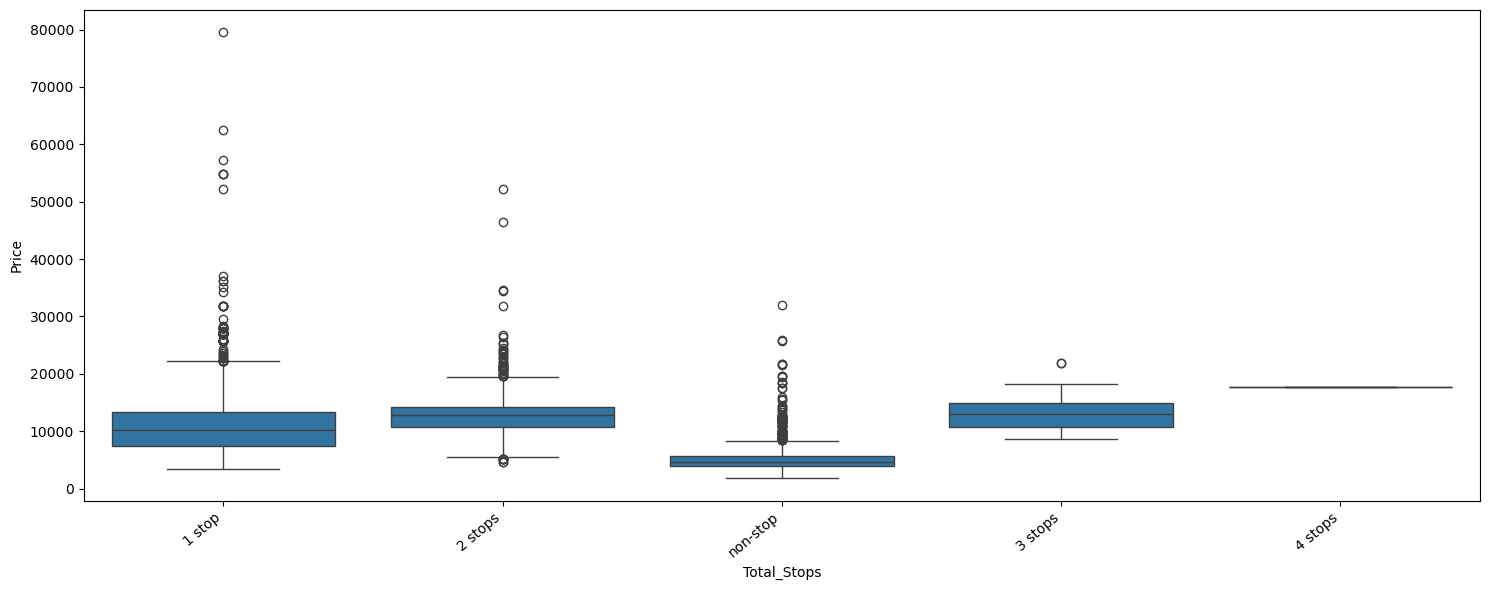

In [41]:
plt.figure(figsize = (15,6))
ax = sns.boxplot(x = 'Total_Stops', y = 'Price', data = flight.sort_values('Price',ascending = False ))
ax.set_xticklabels(ax.get_xticklabels(), rotation = 40, ha = 'right') 
plt.tight_layout()
plt.show()

- Flights with 4 stops show significantly higher prices compared to other categories.
- Flights with fewer stops (e.g., 0 stop or 1 stop) tend to have lower median prices with fewer outliers.
- Numerous outliers exist for flights with 1 stop and 2 stops, this could be due to limited flights availability, and high demand for specific routes. 
- The median price increases as the number of stops increases, suggesting that more stops generally correlate with higher costs.


In [42]:
flight.groupby('Airline').describe()['Price'].sort_values('mean', ascending = False) # by grouping price and Airlines,
                                                                                     # we find the distribution of mean, std etc

,count,mean,std,min,25%,50%,75%,max
Airline,,,,,,,,
Jet Airways Business,6.0,58358.666667,11667.596748,46490.0,52243.0,54747.0,61122.50,79512.0
Jet Airways,3849.0,11643.923357,4258.940578,1840.0,9134.0,11467.0,14151.00,54826.0
Multiple carriers Premium economy,13.0,11418.846154,1717.153936,9845.0,10161.0,11269.0,11269.00,14629.0
Multiple carriers,1196.0,10902.678094,3721.234997,5797.0,7723.0,10197.0,13587.00,36983.0
Air India,1751.0,9612.427756,3901.734561,2050.0,6891.0,9443.0,12219.00,31945.0
Vistara Premium economy,3.0,8962.333333,2915.405518,5969.0,7547.0,9125.0,10459.00,11793.0
Vistara,479.0,7796.348643,2914.298578,3687.0,5403.0,7980.0,9345.00,21730.0
GoAir,194.0,5861.056701,2703.585767,3398.0,3898.0,5135.0,6811.25,22794.0
IndiGo,2053.0,5673.682903,2264.142168,2227.0,4226.0,5000.0,6494.00,22153.0


- If we see the mean pricing for the airlines, Jet Airways Business has the highest price of 58358.67 Rs and Trujet has the least at 4140 Rs.

In [43]:
flight.groupby('Destination').describe()['Price'].sort_values('mean', ascending = False) # by grouping price and Destination
                                                                                         # we find the distribution of mean, std, etc

,count,mean,std,min,25%,50%,75%,max
Destination,,,,,,,,
New Delhi,932.0,11917.716738,7416.086298,3383.0,7240.0,10898.5,13817.0,79512.0
Cochin,4536.0,10540.113536,3782.092549,3876.0,7202.0,10262.0,13344.0,52285.0
Banglore,2871.0,9158.389411,3741.997070,3480.0,5192.0,9345.0,12681.0,31945.0
Delhi,1265.0,5143.918577,1346.487105,3257.0,4030.0,4823.0,5911.0,8541.0
Hyderabad,697.0,5059.708752,4100.504092,1759.0,2647.0,3342.0,5678.0,25139.0
Kolkata,381.0,4789.892388,2190.219021,3145.0,3597.0,3850.0,5277.0,19630.0


- If we see the mean pricing for the destinations the highest is for New Delhi at 11917.71 Rs and lowest is for Kolkata at 4789.89 Rs.

## Data Preprocessing
- Changing Categorical data to Numerical value.
- For further analysis in machine learning we do encoding. There few types in encoding. Here we use onehot encoding, for the variables such as airline, source and destination which doesnot need manual encoding or label encoding. 

### One hot encoding for Airlines

In [44]:
Airline = flight['Airline']
Airline = pd.get_dummies(Airline,drop_first=True).astype(int) #here using one hot encoding for Airlines , we creates dummy columns and
Airline.head()                                                 # concat it with the original column

,Air India,GoAir,IndiGo,Jet Airways,Jet Airways Business,Multiple carriers,Multiple carriers Premium economy,SpiceJet,Trujet,Vistara,Vistara Premium economy
0,0,0,1,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,0
2,0,0,0,1,0,0,0,0,0,0,0
3,0,0,1,0,0,0,0,0,0,0,0
4,0,0,1,0,0,0,0,0,0,0,0


### One hot encoding for Source

In [45]:
Source = flight['Source']
Source = pd.get_dummies(flight['Source'], prefix = 'Source', drop_first=True).astype(int) # here using one hot encoding for Source , we creates dummy columns and 
                                                                                          # concat it with the original column
Source.head()

,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai
0,0,0,0,0
1,0,0,1,0
2,0,1,0,0
3,0,0,1,0
4,0,0,0,0


In [46]:
flight.Destination.unique()

array(['New Delhi', 'Banglore', 'Cochin', 'Kolkata', 'Delhi', 'Hyderabad'],
      dtype=object)

### One hot encoding for Destination

In [47]:
Destination = flight['Destination']
Destination = pd.get_dummies(flight['Destination'],prefix= 'Dest', drop_first=True).astype(int)# here using one hotencoding for Source, we create dummy columns
                                                                      # concat it with the original column                                                                          # concat it with the original column
Destination.head()

,Dest_Cochin,Dest_Delhi,Dest_Hyderabad,Dest_Kolkata,Dest_New Delhi
0,0,0,0,0,1
1,0,0,0,0,0
2,1,0,0,0,0
3,0,0,0,0,0
4,0,0,0,0,1


In [48]:
flight.head()

,Airline,Source,Destination,Route,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Dep_hour,Dep_minute,Arrival_hour,Arrival_minute,Duration_Hours,Duration_Minutes
0,IndiGo,Banglore,New Delhi,BLR → DEL,non-stop,No info,3897,24,3,22,20,1,10,2,50
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,2 stops,No info,7662,1,5,5,50,13,15,7,25
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,2 stops,No info,13882,9,6,9,25,4,25,19,0
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,1 stop,No info,6218,12,5,18,5,23,30,5,25
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,1 stop,No info,13302,1,3,16,50,21,35,4,45


### Concatanation of dummy variables

In [49]:
flight = pd.concat([flight, Airline, Source, Destination], axis = 1) # concat dummy columns to original dataset

### Dropping the columns of Airlines, Source and Destination

In [50]:
flight.drop(columns = ['Airline','Source','Destination'], inplace = True) # as we have already created encoded coumns

In [51]:
flight.head()

,Route,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Dep_hour,Dep_minute,Arrival_hour,Arrival_minute,...,Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Dest_Cochin,Dest_Delhi,Dest_Hyderabad,Dest_Kolkata,Dest_New Delhi
0,BLR → DEL,non-stop,No info,3897,24,3,22,20,1,10,...,0,0,0,0,0,0,0,0,0,1
1,CCU → IXR → BBI → BLR,2 stops,No info,7662,1,5,5,50,13,15,...,0,0,0,1,0,0,0,0,0,0
2,DEL → LKO → BOM → COK,2 stops,No info,13882,9,6,9,25,4,25,...,0,0,1,0,0,1,0,0,0,0
3,CCU → NAG → BLR,1 stop,No info,6218,12,5,18,5,23,30,...,0,0,0,1,0,0,0,0,0,0
4,BLR → NAG → DEL,1 stop,No info,13302,1,3,16,50,21,35,...,0,0,0,0,0,0,0,0,0,1


## Manual encoding for Total_Stops

In [52]:
flight.Total_Stops.unique() # Checking the unique values in total_ stops before doing manual encoding

array(['non-stop', '2 stops', '1 stop', '3 stops', '4 stops'],
      dtype=object)

In [53]:
flight.Total_Stops = flight.Total_Stops.map({'non-stop':0,'1 stop':1,'2 stops':2,'3 stops':3,'4 stops':4}).astype('int64')

In [54]:
flight.head()

,Route,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Dep_hour,Dep_minute,Arrival_hour,Arrival_minute,...,Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Dest_Cochin,Dest_Delhi,Dest_Hyderabad,Dest_Kolkata,Dest_New Delhi
0,BLR → DEL,0,No info,3897,24,3,22,20,1,10,...,0,0,0,0,0,0,0,0,0,1
1,CCU → IXR → BBI → BLR,2,No info,7662,1,5,5,50,13,15,...,0,0,0,1,0,0,0,0,0,0
2,DEL → LKO → BOM → COK,2,No info,13882,9,6,9,25,4,25,...,0,0,1,0,0,1,0,0,0,0
3,CCU → NAG → BLR,1,No info,6218,12,5,18,5,23,30,...,0,0,0,1,0,0,0,0,0,0
4,BLR → NAG → DEL,1,No info,13302,1,3,16,50,21,35,...,0,0,0,0,0,0,0,0,0,1


In [55]:
flight.shape

(10682, 32)

## Drop Route and Additional Info columns

In [56]:
flight.Route.unique() # Checking the unique values in route column

array(['BLR → DEL', 'CCU → IXR → BBI → BLR', 'DEL → LKO → BOM → COK',
       'CCU → NAG → BLR', 'BLR → NAG → DEL', 'CCU → BLR',
       'BLR → BOM → DEL', 'DEL → BOM → COK', 'DEL → BLR → COK',
       'MAA → CCU', 'CCU → BOM → BLR', 'DEL → AMD → BOM → COK',
       'DEL → PNQ → COK', 'DEL → CCU → BOM → COK', 'BLR → COK → DEL',
       'DEL → IDR → BOM → COK', 'DEL → LKO → COK',
       'CCU → GAU → DEL → BLR', 'DEL → NAG → BOM → COK',
       'CCU → MAA → BLR', 'DEL → HYD → COK', 'CCU → HYD → BLR',
       'DEL → COK', 'CCU → DEL → BLR', 'BLR → BOM → AMD → DEL',
       'BOM → DEL → HYD', 'DEL → MAA → COK', 'BOM → HYD',
       'DEL → BHO → BOM → COK', 'DEL → JAI → BOM → COK',
       'DEL → ATQ → BOM → COK', 'DEL → JDH → BOM → COK',
       'CCU → BBI → BOM → BLR', 'BLR → MAA → DEL',
       'DEL → GOI → BOM → COK', 'DEL → BDQ → BOM → COK',
       'CCU → JAI → BOM → BLR', 'CCU → BBI → BLR', 'BLR → HYD → DEL',
       'DEL → TRV → COK', 'CCU → IXR → DEL → BLR',
       'DEL → IXU → BOM → COK', 'CCU 

In [57]:
flight.Additional_Info.unique() # Checking the unique values in additional info column

array(['No info', 'In-flight meal not included',
       'No check-in baggage included', '1 Short layover', 'No Info',
       '1 Long layover', 'Change airports', 'Business class',
       'Red-eye flight', '2 Long layover'], dtype=object)

In [58]:
flight.drop(columns = ['Route' , 'Additional_Info'], axis=1,inplace=True) # Dropping the route and additional columns 

### Heatmap

<Axes: >

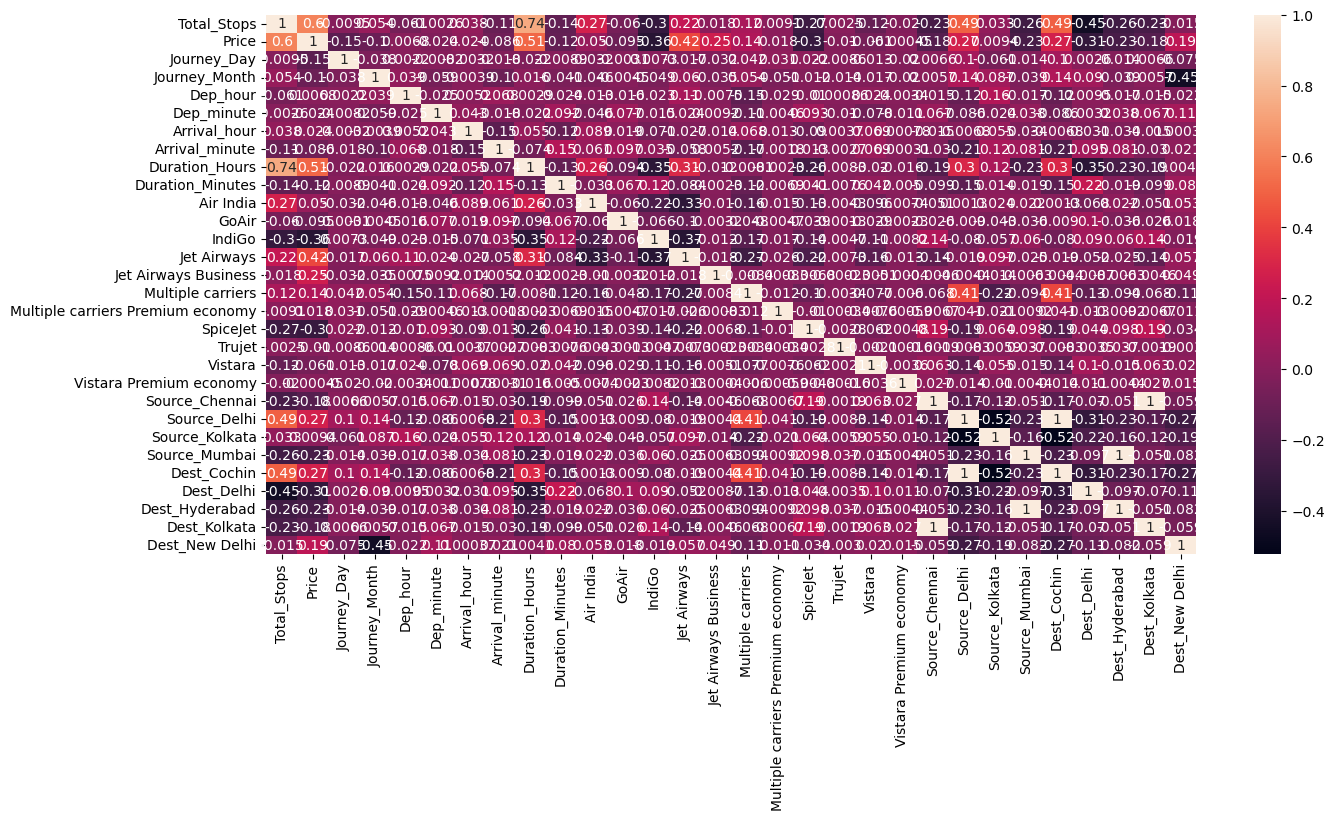

In [59]:
corr_mat = flight.corr()
fig = plt.figure(figsize=(15,7))
sns.heatmap(corr_mat,annot=True)

In [60]:
flight.head()

,Total_Stops,Price,Journey_Day,Journey_Month,Dep_hour,Dep_minute,Arrival_hour,Arrival_minute,Duration_Hours,Duration_Minutes,...,Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Dest_Cochin,Dest_Delhi,Dest_Hyderabad,Dest_Kolkata,Dest_New Delhi
0,0,3897,24,3,22,20,1,10,2,50,...,0,0,0,0,0,0,0,0,0,1
1,2,7662,1,5,5,50,13,15,7,25,...,0,0,0,1,0,0,0,0,0,0
2,2,13882,9,6,9,25,4,25,19,0,...,0,0,1,0,0,1,0,0,0,0
3,1,6218,12,5,18,5,23,30,5,25,...,0,0,0,1,0,0,0,0,0,0
4,1,13302,1,3,16,50,21,35,4,45,...,0,0,0,0,0,0,0,0,0,1


# Building the Machine Learning Models & Evaluation 

In [61]:
# Moving the price column to the end of the table

flight_col = flight.columns.to_list() #converts the column names into
                                      # Python list.
print(flight_col, '\n')
a
new_col = flight_col[:1]+ flight_col[2:] #takes the first column and takes 
                                         # all the columns starting from index 2
new_col.append(flight_col[1]) # combine both columns
print(new_col, '\n')

flight= flight.reindex(columns = new_col) # add the 2nd column to the end of the list
flight.head()

['Total_Stops', 'Price', 'Journey_Day', 'Journey_Month', 'Dep_hour', 'Dep_minute', 'Arrival_hour', 'Arrival_minute', 'Duration_Hours', 'Duration_Minutes', 'Air India', 'GoAir', 'IndiGo', 'Jet Airways', 'Jet Airways Business', 'Multiple carriers', 'Multiple carriers Premium economy', 'SpiceJet', 'Trujet', 'Vistara', 'Vistara Premium economy', 'Source_Chennai', 'Source_Delhi', 'Source_Kolkata', 'Source_Mumbai', 'Dest_Cochin', 'Dest_Delhi', 'Dest_Hyderabad', 'Dest_Kolkata', 'Dest_New Delhi'] 

['Total_Stops', 'Journey_Day', 'Journey_Month', 'Dep_hour', 'Dep_minute', 'Arrival_hour', 'Arrival_minute', 'Duration_Hours', 'Duration_Minutes', 'Air India', 'GoAir', 'IndiGo', 'Jet Airways', 'Jet Airways Business', 'Multiple carriers', 'Multiple carriers Premium economy', 'SpiceJet', 'Trujet', 'Vistara', 'Vistara Premium economy', 'Source_Chennai', 'Source_Delhi', 'Source_Kolkata', 'Source_Mumbai', 'Dest_Cochin', 'Dest_Delhi', 'Dest_Hyderabad', 'Dest_Kolkata', 'Dest_New Delhi', 'Price'] 



,Total_Stops,Journey_Day,Journey_Month,Dep_hour,Dep_minute,Arrival_hour,Arrival_minute,Duration_Hours,Duration_Minutes,Air India,...,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Dest_Cochin,Dest_Delhi,Dest_Hyderabad,Dest_Kolkata,Dest_New Delhi,Price
0,0,24,3,22,20,1,10,2,50,0,...,0,0,0,0,0,0,0,0,1,3897
1,2,1,5,5,50,13,15,7,25,1,...,0,0,1,0,0,0,0,0,0,7662
2,2,9,6,9,25,4,25,19,0,0,...,0,1,0,0,1,0,0,0,0,13882
3,1,12,5,18,5,23,30,5,25,0,...,0,0,1,0,0,0,0,0,0,6218
4,1,1,3,16,50,21,35,4,45,0,...,0,0,0,0,0,0,0,0,1,13302


### Checking for Duplicate Values

In [62]:
print(flight.columns)
print(flight.columns.duplicated())

Index(['Total_Stops', 'Journey_Day', 'Journey_Month', 'Dep_hour', 'Dep_minute',
       'Arrival_hour', 'Arrival_minute', 'Duration_Hours', 'Duration_Minutes',
       'Air India', 'GoAir', 'IndiGo', 'Jet Airways', 'Jet Airways Business',
       'Multiple carriers', 'Multiple carriers Premium economy', 'SpiceJet',
       'Trujet', 'Vistara', 'Vistara Premium economy', 'Source_Chennai',
       'Source_Delhi', 'Source_Kolkata', 'Source_Mumbai', 'Dest_Cochin',
       'Dest_Delhi', 'Dest_Hyderabad', 'Dest_Kolkata', 'Dest_New Delhi',
       'Price'],
      dtype='object')
[False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False]


# Model Building

- We select models like Linear regression, random forest regression since the target variable has numerical data.

In [63]:
# Importing the necessary libraries
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score 
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error
from sklearn import metrics

# Linear Regression
- The linear regression is simple, interpretable and effiecient algorithm for predicting a continuous target variable. 
- However, this model has its limitations like it is sensitive to outliers, and cannot perform well on non linear, complex data. 

In [64]:
X = flight.drop(columns='Price',axis=1)    # Removing Price column from the dependant variables.
y = flight['Price']

### Split Dataset into Training and Testing Sets

In [65]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42)

### Checking the shape of the dataset

In [66]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(8545, 29)
(2137, 29)
(8545,)
(2137,)


### Training the Dataset

In [67]:
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

LinearRegression()

### Predicting the Dataset

In [68]:
y_pred = model_lr.predict(X_test)

### Using the Metrics MAE, MSE, RMSE and R-Squared Value

In [69]:
print("MAE:", metrics.mean_absolute_error(y_test, y_pred))
print('MSE:', metrics.mean_squared_error(y_test, y_pred))
print('RMSE:',np.sqrt(metrics.mean_squared_error(y_test, y_pred)))
print(f'R_Squared_value:', r2_score(y_test, y_pred))

MAE: 1972.9372855148047
MSE: 8202327.557407132
RMSE: 2863.9705929717807
R_Squared_value: 0.6195943729070101


1. Mean Absolute Error (MAE):
Value: 1972.9373
This is the average of the absolute differences between predicted and actual values.
It indicates that, on average, the model’s predictions are off by about 1972.94 units.
However, if seen generally, lower value is better.

2. Mean Squared Error (MSE):
Value: 8202327.5574
This measures the average squared difference between predicted and actual values.
Since it squares the errors, it penalizes larger errors more heavily than MAE, making this metric sensitive to outliers.
This value indicates the model's performance in terms of variance.
However, if seen generally, lower value is better.

3. Root Mean Squared Error (RMSE):
Value: 2863.9705
This is the square root of MSE.
It shows that the average error magnitude is 2863.97 units.
RMSE is often preferred because it balances the scale of the data and penalizes larger errors.
However, if seen generally, lower value is better.

4. R-Squared Value (R²):
Value: 0.6196 (Approximately 61.96%)
R² represents the proportion of variance in the dependent variable that is explained by the model.
A value of 0.6196 means that 61.96% of the variation in y_test is explained by the model, while the rest is unexplained.
R² ranges from 0 to 1, where:
1 means perfect fit.
0 means no explanatory power (model performs no better than a simple mean).
This R² value suggests that the model is moderately good but has room for improvement.

## Summary
The model performs moderately well, as indicated by the R² value of 61.96%.
However, the prediction errors (MAE, RMSE) are relatively high, suggesting potential for improvement in prediction accuracy.

## Improvement
- To improve the model we can improve the feature engineering or use regularization methods.
- We can also check non-linear relationships and test non-linear models.

# Random Forest Regressor 
- This is powerful, non linear algorithm based on decision trees, it can capture the complex and non linear relationships. 
- It combines predictions from multiple decision trees which reduces the risk of overfitting, and it is less sensitive to outliers. 
- It is a slower than linear regression model, and may still overfit on very noisy data. 

### Training the Data Set

In [70]:
rfr = RandomForestRegressor() 
rfr.fit(X_train, y_train)

RandomForestRegressor()

### Predicting the Test Data Set

In [71]:
y_pred = rfr.predict(X_test) #Definng y variable

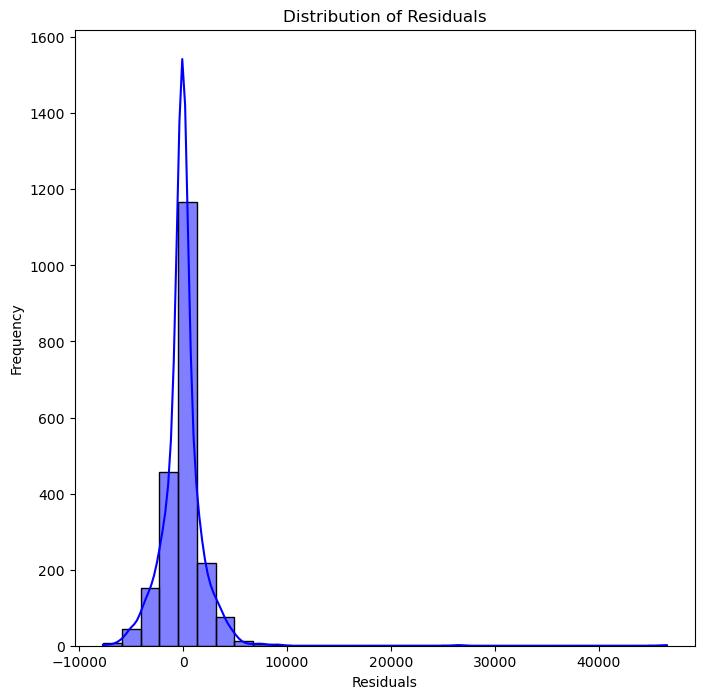

In [72]:
residuals = y_test - y_pred

# Plot the residuals
plt.figure(figsize=(8, 8))
sns.histplot(residuals, kde=True, bins=30, color='blue')  # Using sns.histplot() as distplot() is deprecated
plt.title("Distribution of Residuals")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()

### Interpretation
- Good Fit: The model performs well for most data points, as residuals are close to zero for a large portion of the dataset.
- Areas of Improvement. However we can see a noticeable skewness to the right as the long tail of positive residuals extends higher than 40000. This suggests the model underpredicts some of the actual values.
- Positive skewness can be reduced by using more flexible models like Non Linear Models or Ensemble Methods.
- Handle outliers: Investigate the data points with large residuals to understand why the model struggled with them.
- This analysis highlights that the model fits the majority of the data well but may require further refinement to handle extreme values better.

### Checking the R2 Score on Training Data Set

In [73]:
train_score = rfr.score(X_train, y_train)
print(f"R² Score on Training Data: {train_score}")

R² Score on Training Data: 0.9529654020537192


### Checking the R2 Score on Testing Data Set

In [74]:
test_score = rfr.score(X_test, y_test)
print(f"R² Score on Testing Data: {test_score}")

R² Score on Testing Data: 0.7951660878595799


### Explanation of R2 Score

- R² Score on Training Data:

Value: 0.9529 (approximately 95.29%)
This indicates that the model explains 95.37% of the variance in the training dataset.
A high R² score on training data suggests that the model fits the training data well.

- R² Score on Testing Data:

Value: 0.7951 (approximately 79.51%)
This means that the model explains 79.51% of the variance in the testing dataset.
A lower R² score on the test data compared to the training data indicates a slight decline in performance on unseen data, but it is still relatively high.

### Using the Metrics MAE, MSE, RMSE and R Squared Value

In [75]:
print("MAE:", metrics.mean_absolute_error(y_test, y_pred))
print('MSE:', metrics.mean_squared_error(y_test,y_pred))
print('RMSE:',np.sqrt(metrics.mean_squared_error(y_test,y_pred)))
print(f'R_Squared_value:', r2_score(y_test, y_pred))

MAE: 1181.2627191866004
MSE: 4416640.350670145
RMSE: 2101.5804411609242
R_Squared_value: 0.7951660878595799


1. Mean Absolute Error (MAE):
Value: 1181.2627
This is the average of the absolute differences between predicted and actual values.
It indicates that, on average, the model’s predictions are off by about 1181.2627 units.
However, if seen generally, lower value is better.

2. Mean Squared Error (MSE):
Value: 4416640.3506
This measures the average squared difference between predicted and actual values.
Since it squares the errors, it penalizes larger errors more heavily than MAE, making this metric sensitive to outliers.
This value indicates the model's performance in terms of variance.
However, if seen generally, lower value is better.

3. Root Mean Squared Error (RMSE):
Value: 2101.5804
This is the square root of MSE.
It shows that the average error magnitude is 2101.5804 units.
RMSE is often preferred because it balances the scale of the data and penalizes larger errors.
However, if seen generally, lower value is better.

4. R-Squared Value (R²):
Value: 0.7951 (Approximately 79.51%)
R² represents the proportion of variance in the dependent variable that is explained by the model.
A value of 0.7951 means that 79.51% of the variation in y_test is explained by the model, while the rest is unexplained.
R² ranges from 0 to 1, where:
1 means perfect fit.
0 means no explanatory power (model performs no better than a simple mean).
This R² value suggests that the model is moderately good but has room for improvement.

## Summary
The model performs moderately well, as indicated by the R² value of 79.51%.
However, the prediction errors (MAE, RMSE) are still high, suggesting potential for improvement in prediction accuracy.

## Improvement
- To improve the model we can use hyper parameter tuning.

## Hyper parameter tuning

In [76]:
n_estimators = [int(X) for X in np.linspace(100,2000,10)]   # Number of trees in the forest 
max_depth = [int(X) for X in np.linspace(100,2000,10)]      # Maximum depth of each tree in the forest
min_samples_split = [2,4,6,8,10,12,14]                      # Minimum samples required to split an internal node 
min_samples_leaf = [1,3,5,7,8,100]                          # Minimum samples required at a leaf node
max_features = ['sqrt','log2', 'auto',None]                 # Number of features to consider when looking for the best split

random_search = {
    'n_estimators' : n_estimators,
    'max_depth' : max_depth,
    'min_samples_split' : min_samples_split,
    'min_samples_leaf' : min_samples_leaf,
    'max_features' : max_features,
}
random_search

{'n_estimators': [100, 311, 522, 733, 944, 1155, 1366, 1577, 1788, 2000],
 'max_depth': [100, 311, 522, 733, 944, 1155, 1366, 1577, 1788, 2000],
 'min_samples_split': [2, 4, 6, 8, 10, 12, 14],
 'min_samples_leaf': [1, 3, 5, 7, 8, 100],
 'max_features': ['sqrt', 'log2', 'auto', None]}

## Randomized Search CV

In [77]:
rfr_tuned = RandomizedSearchCV(estimator = rfr, param_distributions= random_search, n_iter=10, cv= 5, verbose = 2, random_state=51, n_jobs = 1)

### Training the Data Set

In [78]:
rfr_tuned.fit(X_train, y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END max_depth=2000, max_features=sqrt, min_samples_leaf=7, min_samples_split=6, n_estimators=1788; total time=   6.7s
[CV] END max_depth=2000, max_features=sqrt, min_samples_leaf=7, min_samples_split=6, n_estimators=1788; total time=   6.7s
[CV] END max_depth=2000, max_features=sqrt, min_samples_leaf=7, min_samples_split=6, n_estimators=1788; total time=   6.7s
[CV] END max_depth=2000, max_features=sqrt, min_samples_leaf=7, min_samples_split=6, n_estimators=1788; total time=   6.7s
[CV] END max_depth=2000, max_features=sqrt, min_samples_leaf=7, min_samples_split=6, n_estimators=1788; total time=   6.7s
[CV] END max_depth=311, max_features=log2, min_samples_leaf=1, min_samples_split=2, n_estimators=1155; total time=   8.1s
[CV] END max_depth=311, max_features=log2, min_samples_leaf=1, min_samples_split=2, n_estimators=1155; total time=   7.9s
[CV] END max_depth=311, max_features=log2, min_samples_leaf=1, min_samples_split

RandomizedSearchCV(cv=5, estimator=RandomForestRegressor(), n_jobs=1,
                   param_distributions={'max_depth': [100, 311, 522, 733, 944,
                                                      1155, 1366, 1577, 1788,
                                                      2000],
                                        'max_features': ['sqrt', 'log2', 'auto',
                                                         None],
                                        'min_samples_leaf': [1, 3, 5, 7, 8,
                                                             100],
                                        'min_samples_split': [2, 4, 6, 8, 10,
                                                              12, 14],
                                        'n_estimators': [100, 311, 522, 733,
                                                         944, 1155, 1366, 1577,
                                                         1788, 2000]},
                   random_state=51, verbose=2)

### Finding the Best Parameters

In [79]:
rfr_tuned.best_params_

{'n_estimators': 100,
 'min_samples_split': 10,
 'min_samples_leaf': 3,
 'max_features': None,
 'max_depth': 522}

## Testing the Data Set

In [80]:
prediction = rfr_tuned.predict(X_test)

### Distribution of Residuals

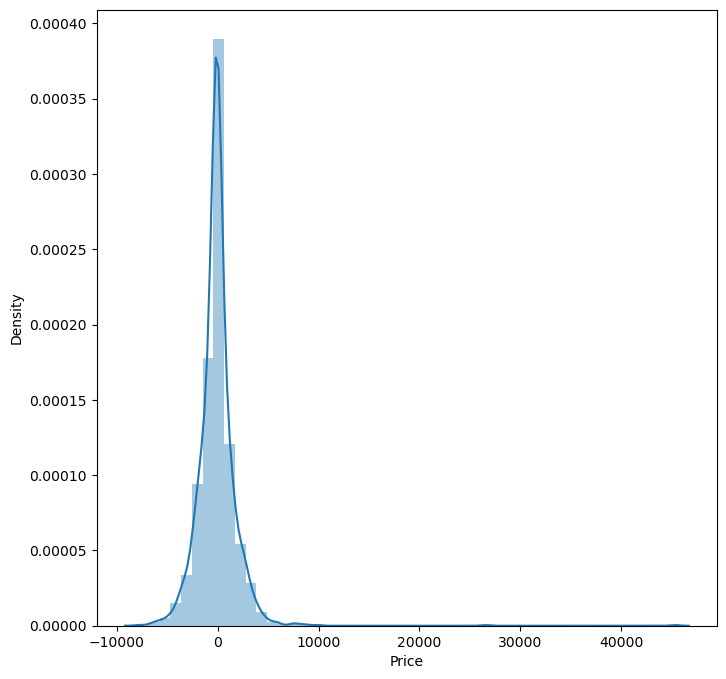

In [81]:
plt.figure(figsize = (8,8))
sns.distplot(y_test - prediction)
plt.show()

- Residuals are more tightly centered around zero, also it has a narrow spread with reduced tail which indicates few errors and improved predictions after Hyper Parameter Tuning.
- Fewer outliers indicate that the model has generalised better.

### Using the Metrics MAE, MSE, RMSE and R Squared Value

In [82]:
print("MAE:", metrics.mean_absolute_error(y_test, prediction))
print('MSE:', metrics.mean_squared_error(y_test,prediction))
print('RMSE:',np.sqrt(metrics.mean_squared_error(y_test,prediction)))
print(f'R_Squared_value:', r2_score(y_test, prediction))

MAE: 1154.2138226890052
MSE: 4047769.6248028674
RMSE: 2011.906962263133
R_Squared_value: 0.8122734880222412


1. Mean Absolute Error (MAE):
Value: 1154.2138
This is the average of the absolute differences between predicted and actual values.
It indicates that, on average, the model’s predictions are off by about 1181.6781 units.
However, if seen generally, lower value is better.

2. Mean Squared Error (MSE):
Value: 4047769.6248
This measures the average squared difference between predicted and actual values.
Since it squares the errors, it penalizes larger errors more heavily than MAE, making this metric sensitive to outliers.
This value indicates the model's performance in terms of variance.
However, if seen generally, lower value is better.

3. Root Mean Squared Error (RMSE):
Value: 2011.9069
This is the square root of MSE.
It shows that the average error magnitude is 2011.9069 units.
RMSE is often preferred because it balances the scale of the data and penalizes larger errors.
However, if seen generally, lower value is better.

4. R-Squared Value (R²):
Value: 0.8122 (Approximately 81.22%)
R² represents the proportion of variance in the dependent variable that is explained by the model.
A value of 0.8122 means that 81.22% of the variation in y_test is explained by the model, while the rest is unexplained.
R² ranges from 0 to 1, where:
1 means perfect fit.
0 means no explanatory power (model performs no better than a simple mean).
This R² value suggests that the model is moderately good but has room for improvement.

## Summary
The model performs moderately well, as indicated by the R² value of 81.18%.
However, the prediction errors (MAE, RMSE) are still high, suggesting potential for improvement in prediction accuracy.

## Findings from Metrics

#### Comparison of MAE
|MAE|Value|
|---|-----|
|Linear Regressor|1972.937|
|Random Forest Regressor|1181.262|
|Random Forest Regressor with Tuned Parameters|1154.213|

- If we see the values of MAE(Mean Absolute Error) the least value can be seen for the Random Forest Regressor with Tuned Parameters at 1154.213.
- The linear regression model has the highest error, which means its predictions are less accurate compared to the other models. It struggles to capture the underlying patterns in the data.
- We can see a significant improvement in the values of Random Forest Regression compared to Linear Regression. We can see a further improvement with Tuned Parameters.

#### Comparison of MSE
|MSE|Value|
|---|-----|
|Linear Regressor|8202327.557|
|Random Forest Regressor|4416640.350|
|Random Forest Regressor with Tuned Parameters|4047769.624|

- Seeing the values of MSE(Mean Squared Error) the least value can be observed for Random Forest Regressor with Tuned Parameters again at 4047769.624.
- The Linear Regressor has the largest Squared Error which shows that it doesnt predict the value well. However, we can see an improvement in the Random Forest Regressor model. However Random Forest Regressor with Tuned Parameters predicts the value best (Since its value is the lowest). 

#### Comparison of RMSE
|RMSE|Value|
|----|-----|
|Linear Regressor|2863.970|
|Random Forest Regressor|2101.580|
|Random Forest Regressor with Tuned Parameters|2011.906|

- Seeing the values of RMSE(Root Mean Squared Error) the least value can be again be observed again for Random Forest Regressor with Tuned Parameters at 2011.906.

#### Comparison of R-Squared Value
|R-Squared|Value|
|---------|-----|
|Linear Regressor|0.619|
|Random Forest Regressor|0.795|
|Random Forest Regressor with Tuned Parameters|0.812|

- Seeing the R-Squared values the Highest value can be observed again for Random Forest Regressor with Tuned Parameters at 0.812 which is significantly better compared to the other two models.
- This indicates that the Random Forest Regressor with Tuned Parameters model is capturing 81% of the variance in the target variable, which shows that it fits the data much better.

# Conclusion

- The Random Forest Regressor with Hyperparameter Tuning was identified as the best performing model for this data set.
- It effectively captured non linear patterns and provided accurate predictions for flight fares.
- According to the comparison of the different metrics, the Random Forest Regressor with Tuned Parameters performed the best among all three.

# Recommendations

- Airlines and travel agencies can use the model to predict competitive fares and optimize revenue.
- Customers can use the model to compare expected prices based on travel preferences such as time, duration, and stops.

# Limitations and Improvements
- The model’s performance could be further improved with more detailed data, such as real-time demand, seasonal trends, and fare categories.
- Incorporate external factors like weather, holidays, and real-time seat availability to improve prediction accuracy.
- Explore deep learning techniques for further performance improvements.